- Johan Moises Cardona Rosales - 202201405
- Estiben Yair Lopez Leveron - 202204578

# Tarea #1 - Limpieza y análisis inicial de datos con Python y Pandas
**Seminario de Sistemas 2 - USAC**

Dataset: `dataset_sucio.csv` (5000 registros de clientes)

Este notebook documenta el proceso completo de:
1. Exploración del dataset en su estado original
2. Eliminación de duplicados
3. Tratamiento de celdas vacías (valores faltantes)
4. Estandarización de valores y formatos
5. Comparación mediante tablas pivote (antes vs. después)
6. Visualizaciones y conclusiones

## 1. Importar librerías y cargar el dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

df = pd.read_csv('dataset_sucio.csv')
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
df.head(10)

Filas: 5000, Columnas: 7


,id_cliente,nombre,genero,fecha_registro,gasto_q,ciudad,categoria
0,502609,Paola Morales,m,2026-02-27,NaN,Antigua,Retail
1,500588,ANA DIAZ,f,2026-02-24,371.80,Villa Nueva,Services
2,502408,Maria Paz,m,2026-01-15,"373,33",quetzaltenango,retail
3,501688,Ana Mejia,f,2026-01-18,361.23,Quetzaltenango,Education
4,502916,Carlos Mendez,f,29/01/2026,"339,01",Amatitlan,Retail
5,504200,Oscar Rojas,m,2026-01-09,138.22,Antigua,RETAIL
6,502029,Isabel Ramirez,m,2026-02-05,"166,31",Villa Nueva,SERVICES
7,501366,Pedro Herrera,m,12/02/2026,"405,62",Amatitlan,Education
8,502614,Patricia Soto,F,2026-01-11,222.88,guatemala,Retail
9,502794,Pablo Perez,M,2026-02-06,"287,37",Escuintla,Retail


## 2. Exploración inicial (estado original)

Antes de limpiar nada, revisamos la estructura, los tipos de dato y la cantidad de valores
faltantes/duplicados. Guardamos una copia del dataframe original (`df_original`) para poder
compararla más adelante con el dataframe ya limpio.

In [2]:
df_original = df.copy()

print("Tipos de dato:")
print(df.dtypes)
print()
print("Valores nulos por columna:")
print(df.isnull().sum())
print()
print(f"Filas duplicadas (registro completo): {df.duplicated().sum()}")
print(f"Filas duplicadas por id_cliente: {df.duplicated(subset=['id_cliente']).sum()}")

Tipos de dato:
id_cliente        int64
nombre              str
genero              str
fecha_registro      str
gasto_q             str
ciudad              str
categoria           str
dtype: object

Valores nulos por columna:
id_cliente          0
nombre              0
genero             60
fecha_registro      0
gasto_q           505
ciudad            157
categoria           0
dtype: int64

Filas duplicadas (registro completo): 100
Filas duplicadas por id_cliente: 100


In [3]:
print("Valores únicos en 'genero':")
print(sorted(df['genero'].dropna().unique().tolist()))
print()
print("Valores únicos en 'ciudad':")
print(sorted(df['ciudad'].dropna().unique().tolist()))
print()
print("Valores únicos en 'categoria':")
print(sorted(df['categoria'].dropna().unique().tolist()))

Valores únicos en 'genero':
[' ', ' f ', ' m ', 'F', 'M', 'f', 'm']

Valores únicos en 'ciudad':
[' ', '  Amatitlan', '  Antigua', '  Chimaltenango', '  Escuintla', '  Guatemala', '  Mixco', '  Quetzaltenango', '  Villa Nueva', 'AMATITLAN', 'ANTIGUA', 'Amatitlan', 'Amatitlan ', 'Antigua', 'Antigua ', 'CHIMALTENANGO', 'Chimaltenango', 'Chimaltenango ', 'ESCUINTLA', 'Escuintla', 'Escuintla ', 'GUATEMALA', 'Guatemala', 'Guatemala ', 'MIXCO', 'Mixco', 'Mixco ', 'QUETZALTENANGO', 'Quetzaltenango', 'Quetzaltenango ', 'VILLA NUEVA', 'Villa Nueva', 'Villa Nueva ', 'amatitlan', 'antigua', 'chimaltenango', 'escuintla', 'guatemala', 'mixco', 'quetzaltenango', 'villa nueva']

Valores únicos en 'categoria':
['EDUCATION', 'Education', 'Education ', 'FOOD', 'Food', 'Food ', 'RETAIL', 'Retail', 'Retail ', 'SERVICES', 'Services', 'Services ', 'education', 'food', 'retail', 'services']


**Hallazgos del estado original:**
- 100 filas duplicadas por `id_cliente`.
- Valores faltantes en `genero` (60), `gasto_q` (505) y `ciudad` (157).
- `genero` tiene variantes como `' m '`, `'M'`, `'f'`, `'F'` e incluso un espacio en blanco.
- `ciudad` y `categoria` mezclan mayúsculas, minúsculas y espacios extra (ej. `'Antigua'`, `'  ANTIGUA'`, `'antigua '`).
- `fecha_registro` mezcla dos formatos: `AAAA-MM-DD` y `DD/MM/AAAA`.
- `gasto_q` está guardado como texto y mezcla separador decimal de punto y de coma (ej. `304.89` vs `413,33`).
- `nombre` tiene espacios extra al inicio/final o dobles espacios internos.

## 3. Eliminación de duplicados

In [4]:
filas_antes = df.shape[0]
df = df.drop_duplicates(subset=['id_cliente'], keep='first')
filas_despues = df.shape[0]

print(f"Filas antes: {filas_antes}")
print(f"Filas después: {filas_despues}")
print(f"Duplicados eliminados: {filas_antes - filas_despues}")

Filas antes: 5000
Filas después: 4900
Duplicados eliminados: 100


## 4. Tratamiento de celdas vacías

Decisiones tomadas por columna:
- **`genero`**: se rellena con `'No especificado'`, ya que no hay forma correcta de inferir el género faltante y eliminar la fila perdería información útil de otras columnas.
- **`ciudad`**: se rellena con `'No especificado'` por la misma razón.
- **`gasto_q`**: primero se debe convertir a numérico (ver estandarización). Los valores faltantes se rellenan con la **mediana** de la columna, ya que es más robusta ante valores extremos que el promedio.

In [5]:
df['genero'] = df['genero'].fillna('No especificado')
df['ciudad'] = df['ciudad'].fillna('No especificado')

print("Nulos restantes tras el primer tratamiento:")
print(df.isnull().sum())

Nulos restantes tras el primer tratamiento:
id_cliente          0
nombre              0
genero              0
fecha_registro      0
gasto_q           497
ciudad              0
categoria           0
dtype: int64


## 5. Estandarización de valores y formatos

In [6]:
# Nombre: quitar espacios extra al inicio/final y espacios dobles internos
df['nombre'] = df['nombre'].str.strip().str.replace(r'\s+', ' ', regex=True).str.title()

# Genero: quitar espacios, pasar a mayúscula y unificar a M / F
df['genero'] = df['genero'].str.strip().str.upper()
df['genero'] = df['genero'].replace({'': 'No especificado'})

# Ciudad: quitar espacios extra y capitalizar
df['ciudad'] = df['ciudad'].str.strip().str.title()

# Categoria: quitar espacios extra y capitalizar
df['categoria'] = df['categoria'].str.strip().str.title()

print("Valores únicos en 'genero' tras estandarizar:", sorted(df['genero'].unique().tolist()))
print("Valores únicos en 'ciudad' tras estandarizar:", sorted(df['ciudad'].unique().tolist()))
print("Valores únicos en 'categoria' tras estandarizar:", sorted(df['categoria'].unique().tolist()))

Valores únicos en 'genero' tras estandarizar: ['F', 'M', 'NO ESPECIFICADO', 'No especificado']
Valores únicos en 'ciudad' tras estandarizar: ['', 'Amatitlan', 'Antigua', 'Chimaltenango', 'Escuintla', 'Guatemala', 'Mixco', 'No Especificado', 'Quetzaltenango', 'Villa Nueva']
Valores únicos en 'categoria' tras estandarizar: ['Education', 'Food', 'Retail', 'Services']


In [7]:
# Fecha: unificar formato mixto (AAAA-MM-DD y DD/MM/AAAA) a datetime único
def parsear_fecha(valor):
    for formato in ('%Y-%m-%d', '%d/%m/%Y'):
        try:
            return pd.to_datetime(valor, format=formato)
        except (ValueError, TypeError):
            continue
    return pd.NaT

df['fecha_registro'] = df['fecha_registro'].apply(parsear_fecha)

print("Rango de fechas:", df['fecha_registro'].min(), "a", df['fecha_registro'].max())
print("Fechas no reconocidas:", df['fecha_registro'].isnull().sum())

Rango de fechas: 2026-01-01 00:00:00 a 2026-03-01 00:00:00
Fechas no reconocidas: 0


In [8]:
# Gasto: quitar comillas, unificar separador decimal (coma -> punto) y convertir a float
df['gasto_q'] = (
    df['gasto_q']
    .astype(str)
    .str.replace(',', '.', regex=False)
    .replace('nan', np.nan)
    .astype(float)
)

mediana_gasto = df['gasto_q'].median()
df['gasto_q'] = df['gasto_q'].fillna(mediana_gasto)

print(f"Mediana usada para rellenar gasto_q: Q{mediana_gasto:.2f}")
print("Nulos restantes en todo el dataframe:")
print(df.isnull().sum())

Mediana usada para rellenar gasto_q: Q251.80
Nulos restantes en todo el dataframe:
id_cliente        0
nombre            0
genero            0
fecha_registro    0
gasto_q           0
ciudad            0
categoria         0
dtype: int64


## 6. Exploración mediante tablas pivote: antes vs. después

Comparamos el dataframe **original** (`df_original`) contra el dataframe **limpio** (`df`)
usando la misma agrupación, para evidenciar el impacto de la limpieza.

In [9]:
# --- Tabla pivote ANTES (datos originales, sin limpiar) ---
df_original_temp = df_original.copy()
df_original_temp['ciudad_norm'] = df_original_temp['ciudad'].astype(str).str.strip().str.title()
df_original_temp['categoria_norm'] = df_original_temp['categoria'].astype(str).str.strip().str.title()
df_original_temp['gasto_num'] = pd.to_numeric(
    df_original_temp['gasto_q'].astype(str).str.replace(',', '.', regex=False), errors='coerce'
)

pivote_antes = pd.pivot_table(
    df_original_temp,
    values='gasto_num',
    index='ciudad_norm',
    columns='categoria_norm',
    aggfunc='mean'
).round(2)
pivote_antes

categoria_norm,Education,Food,Retail,Services
ciudad_norm,,,,
,198.40,232.05,249.35,246.99
Amatitlan,236.49,226.68,240.16,270.11
Antigua,244.72,246.28,252.84,226.14
Chimaltenango,262.17,262.01,269.26,264.37
Escuintla,271.03,261.88,267.72,278.12
Guatemala,249.72,251.66,225.11,238.39
Mixco,255.12,254.03,240.91,245.61
Quetzaltenango,241.67,279.20,258.90,256.13
Villa Nueva,244.06,240.36,255.44,228.52


In [10]:
# --- Tabla pivote DESPUÉS (datos ya limpios) ---
pivote_despues = pd.pivot_table(
    df,
    values='gasto_q',
    index='ciudad',
    columns='categoria',
    aggfunc='mean'
).round(2)
pivote_despues

categoria,Education,Food,Retail,Services
ciudad,,,,
,201.96,232.05,249.72,247.64
Amatitlan,241.25,229.16,242.19,264.49
Antigua,245.74,253.47,255.63,227.72
Chimaltenango,260.87,261.74,267.86,262.29
Escuintla,269.17,260.48,264.80,275.56
Guatemala,248.24,250.27,226.74,238.74
Mixco,256.44,253.79,244.76,247.56
No Especificado,213.02,271.19,239.00,274.92
Quetzaltenango,240.04,278.23,255.91,257.17


**Interpretación:**
La tabla "antes" tiene columnas y filas repetidas por las mismas ciudades/categorías escritas de
forma distinta (ej. `Antigua` y `Antigua ` cuentan como grupos separados), lo que **diluye el
promedio real de gasto por ciudad/categoría** y hace imposible comparar correctamente los segmentos.
Después de estandarizar texto, unificar fechas y convertir `gasto_q` a numérico, la tabla "después"
consolida cada ciudad y categoría en una sola fila/columna, dando promedios de gasto confiables y
comparables. Esto demuestra directamente cómo la calidad de los datos afecta la validez de cualquier
análisis o decisión basada en ellos (criterio ISO 25000: consistencia y exactitud).

## 7. Visualizaciones (datos ya limpios)

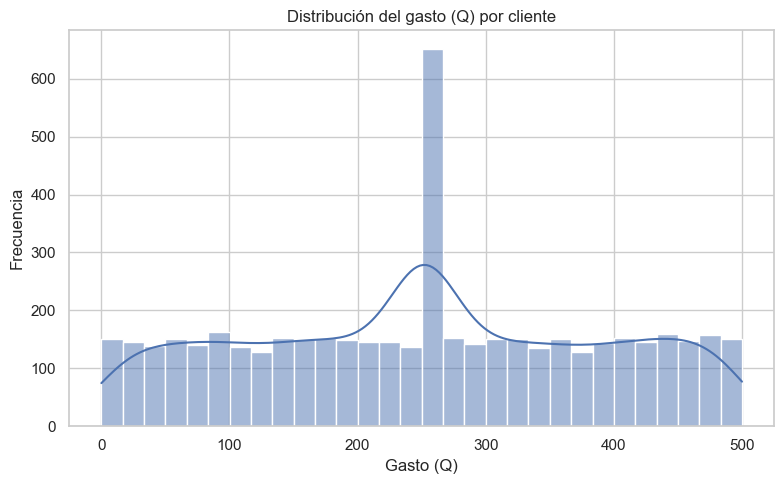

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df['gasto_q'], bins=30, kde=True, ax=ax, color='#4C72B0')
ax.set_title('Distribución del gasto (Q) por cliente')
ax.set_xlabel('Gasto (Q)')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

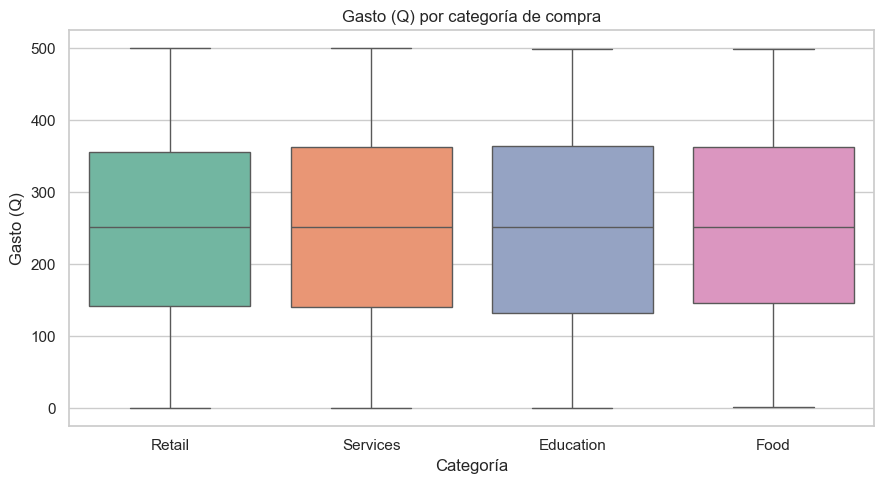

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='categoria', y='gasto_q', hue='categoria', ax=ax, palette='Set2', legend=False)
ax.set_title('Gasto (Q) por categoría de compra')
ax.set_xlabel('Categoría')
ax.set_ylabel('Gasto (Q)')
plt.tight_layout()
plt.show()

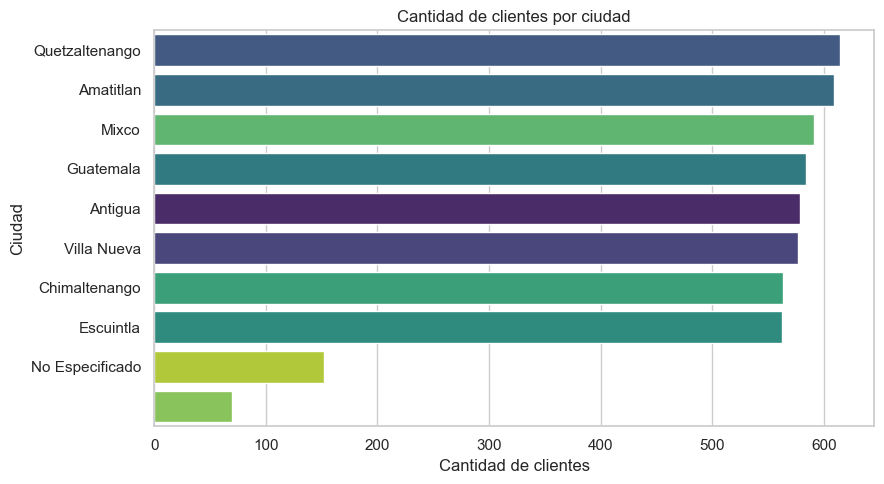

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
orden_ciudades = df['ciudad'].value_counts().index
sns.countplot(data=df, y='ciudad', hue='ciudad', order=orden_ciudades, ax=ax, palette='viridis', legend=False)
ax.set_title('Cantidad de clientes por ciudad')
ax.set_xlabel('Cantidad de clientes')
ax.set_ylabel('Ciudad')
plt.tight_layout()
plt.show()

**Interpretación de las visualizaciones:**
- El histograma muestra que el gasto de los clientes se concentra principalmente en el rango bajo-medio, sin una cola extrema que distorsione la mediana usada para rellenar los valores faltantes.
- El boxplot por categoría permite comparar el rango de gasto entre Retail, Services, Education y Food ya de forma consistente (antes de limpiar, esta comparación hubiera estado fragmentada por las variantes de texto).
- El conteo de clientes por ciudad confirma que Guatemala, Antigua y Quetzaltenango concentran la mayor cantidad de clientes.

## 8. Exportar el dataset limpio

In [14]:
df.to_csv('dataset_limpio.csv', index=False)
print("Dataset limpio exportado como 'dataset_limpio.csv'")
print(f"Forma final: {df.shape}")
df.head(10)

Dataset limpio exportado como 'dataset_limpio.csv'
Forma final: (4900, 7)


,id_cliente,nombre,genero,fecha_registro,gasto_q,ciudad,categoria
0,502609,Paola Morales,M,2026-02-27,251.80,Antigua,Retail
1,500588,Ana Diaz,F,2026-02-24,371.80,Villa Nueva,Services
2,502408,Maria Paz,M,2026-01-15,373.33,Quetzaltenango,Retail
3,501688,Ana Mejia,F,2026-01-18,361.23,Quetzaltenango,Education
4,502916,Carlos Mendez,F,2026-01-29,339.01,Amatitlan,Retail
5,504200,Oscar Rojas,M,2026-01-09,138.22,Antigua,Retail
6,502029,Isabel Ramirez,M,2026-02-05,166.31,Villa Nueva,Services
7,501366,Pedro Herrera,M,2026-02-12,405.62,Amatitlan,Education
8,502614,Patricia Soto,F,2026-01-11,222.88,Guatemala,Retail
9,502794,Pablo Perez,M,2026-02-06,287.37,Escuintla,Retail
